### Импорты

In [270]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

sns.set_theme(palette='winter')

### Константы

In [271]:
ROOT_DIR = Path.cwd()
DATA_DIR = ROOT_DIR / 'data'
BOSTON_CSV = DATA_DIR / 'boston.csv'

### Основная часть

1.  Загрузите данные из файла "boston.csv"  о недвижимости в различных районах Бостона.

Столбцы (признаки) имеют следующий смысл: 
- CRIM – уровень преступности 
- ZN  –  доля жилых земель, разделенных на участки площадью более 25 000 кв.футов 
- INDUS – доля площадей, не связанных с розничной торговлей 
- CHAS – наличие реки (1, если граничит с рекой; 0 в противном случае) 
- NOX – качество воздуха (концентрация оксидов азота) 
- RM – среднее количество комнат в доме 
- AGE – доля жилых помещений, построенных владельцами до 1940 года 
- DIS – взвешенные расстояния до пяти бостонских центров занятости 
- RAD – транспортная  доступность (индекс  доступности  радиальных автомагистралей) 
- TAX – налоги (ставка налога на 10 000 долларов США) 
- PTRATIO – соотношение количества учеников и учителей 
- B – нормированное значение доли афроамериканцев среди жителей 
- LSTAT – процент населения с низким социальным статусом 
- MEDV  –  медианная цена недвижимости  (тыс. $)  –  это и будет целевой признак

In [272]:
df = pd.read_csv(BOSTON_CSV, sep=',')

In [273]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [274]:
duplicates = df.duplicated()
df[duplicates]

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV


2.  Проверьте, что у всех загруженных данных числовой тип.

*Dtype всех колонок float64*

In [275]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    float64
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(14)
memory usage: 55.5 KB


3.  Проверьте, есть  ли  по  каким-либо  признакам  отсутствующие  данные.  Если отсутствующие данные есть – заполните их медианным значением.

*В данных нет пропусков*

In [276]:
df.isna().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

4.  Посчитайте коэффициент  корреляции  для  всех  пар  признаков. 

Подсказка: воспользуйтесь методом corr() для датафрейма.

In [277]:
corr_matrix = df.corr(numeric_only=True)

5.  С  помощью  одной  из  библиотек  визуализации  постройте  тепловую  карту (heatmap) по корреляционной матрице. 

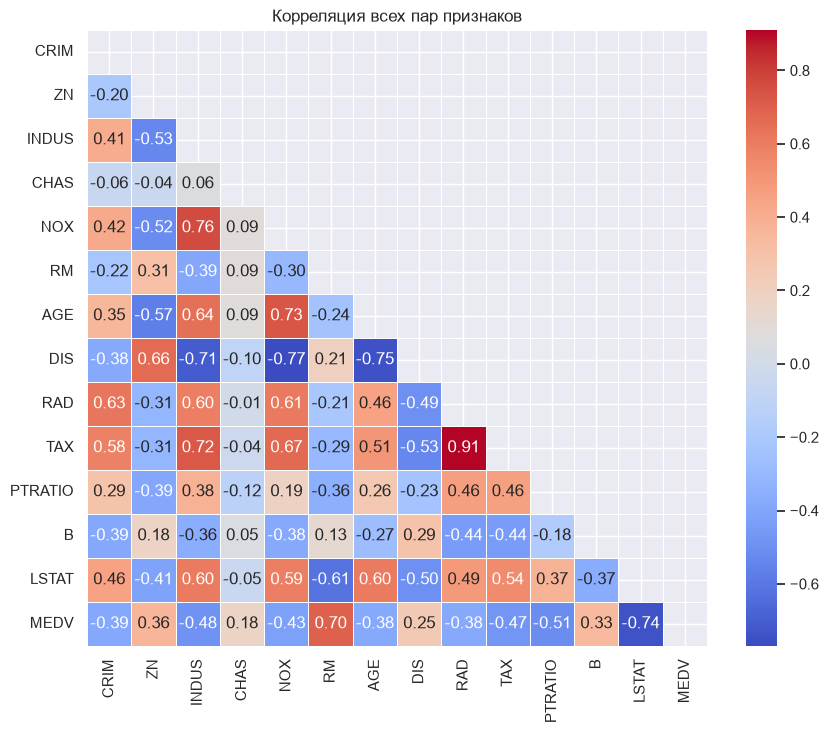

In [278]:
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Корреляция всех пар признаков')
plt.show()

6.  Выберите от 4 до 6 признаков (на свое усмотрение), которые в наибольшей степени коррелируют с целевым признаком (ценой недвижимости). 

Справка.

Коэффициент корреляции изменяется от -1 до 1. Значение -1 означает точную обратно-пропорциональную зависимость (чем меньше одна переменная, тем  больше  вторая,  и наоборот). 

Значение  1  означает  точную  прямо-пропорциональную  зависимость. 

Значение  0  означает  полное  отсутствие зависимости. 

Таким образом, чем ближе модуль  коэффициента корреляции к 1, тем сильнее прослеживается зависимость между признаками.

In [279]:
corr_matrix['MEDV'].sort_values(ascending=False)

MEDV       1.000000
RM         0.695360
ZN         0.360445
B          0.333461
DIS        0.249929
CHAS       0.175260
AGE       -0.376955
RAD       -0.381626
CRIM      -0.388305
NOX       -0.427321
TAX       -0.468536
INDUS     -0.483725
PTRATIO   -0.507787
LSTAT     -0.737663
Name: MEDV, dtype: float64

По построенной матрице целесообразно взять наиболее коррелирующие с целевой переменной признаки: `RM`, `LSTAT`, `PTRATIO`, `INDUS`, `TAX`, `NOX`

In [280]:
x_cols = ['RM', 'LSTAT', 'PTRATIO', 'INDUS', 'TAX', 'NOX']
y_col = 'MEDV'

7.  Для каждого из выбранных признаков в паре с целевым признаком постройте точечную диаграмму (диаграмму рассеяния). 

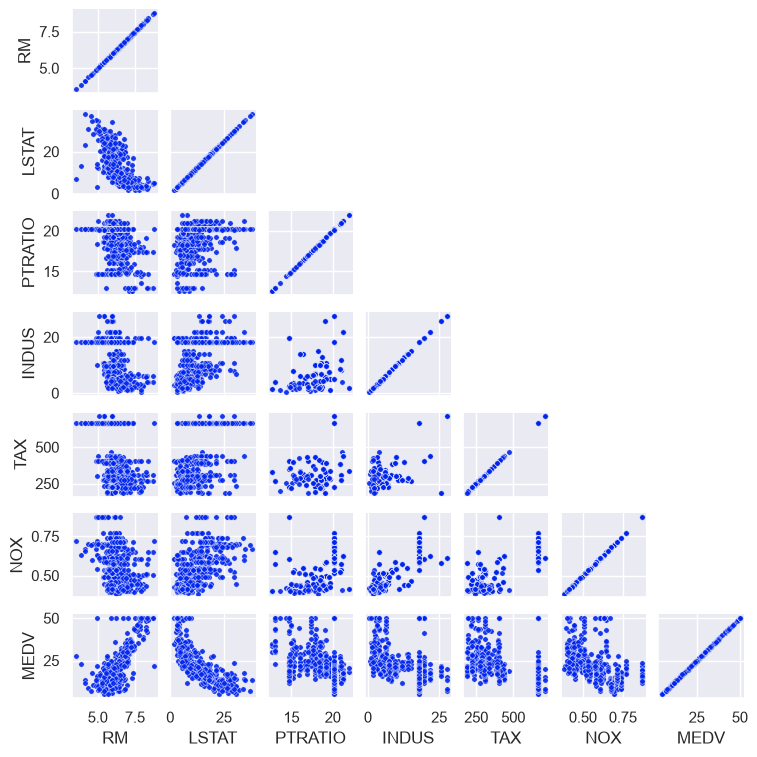

In [281]:
# Диаграммы рассеяния для факторных признаков и целевого признака
sns.pairplot(
    df[x_cols + [y_col]],
    diag_kind=None,
    corner=True,
    height=1.1,
    plot_kws={'s': 15, 'alpha': 0.9}
)
plt.show()

8.  Визуально  убедитесь,  что  связь  между  выбранным  признаком  и  целевым прослеживается.  

Если  на  основе  графика  считаете,  что  зависимости  нет  – исключите этот признак из дальнейшего рассмотрения (но при этом как минимум 3 признака должно остаться в любом случае).

Исходя из диаграммы попарных взаимосвязей между переменными, целевой признак `MEDV` действительно имеет корреляцию с признаками:

- `RM` - сильная положительная
- `LSTAT` - сильная отрицательная
- `PTRATIO` - слабая отрицательная
- `INDUS` - слабая отрицательная
- `TAX` - слабая отрицательная
- `NOX` - слабая отрицательная

Все признаки являются непрерывными.

Однако между признаками `RM` и `LSTAT` присутствует сильная отрицательная корреляция, которую необходимо убрать для избежания мультиколлинеарности.

Объединим признаки `RM` и `LSTAT` при помощи метода понижения размерности `PCA`.

9.  Сформируйте список факторных признаков и целевую переменную.

10. Выполните  разбиение  датасета  на  обучающую  и  тестовую  выборки  в соотношении 75:25. При формировании обучающей и тестовой выборок строки из исходного  датафрейма  должны  выбираться  в  случайном  порядке. 

Подсказка: можно  воспользоваться  функцией  train_test_split  из  библиотеки sklearn.model_selection. 

In [282]:
config_tts = {
    'random_state': 42,
    'test_size': .25,
    'shuffle': True
}

In [283]:
# Выделям признаки из общего датасета
x_df = df[x_cols]
y_df = df[y_col]

# Разбиваем на тренировочную и тестовую части
X_train, X_test, y_train, y_test = train_test_split(x_df, y_df, **config_tts)

# Стандартизируем факторные признаки (обучаем scaler только на train части для избежании утечки данных)
scaler = StandardScaler()
# вернем тип датафрейма для удобства
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

# Применяем PCA для признаков RM и LSTAT (обучаем PCA только на train части для избежании утечки данных)
pca_cols = ['RM', 'LSTAT']
pca = PCA(n_components=1)
rm_lstat_train = pca.fit_transform(X_train_scaled[pca_cols])
rm_lstat_test = pca.transform(X_test_scaled[pca_cols])

# Добавим новый признак RM_LSTAT и удалил признаки RM и LSTAT
new_feature_name = 'RM_LSTAT'
X_train_scaled[new_feature_name] = rm_lstat_train
X_train_scaled = X_train_scaled.drop(columns=pca_cols)
X_test_scaled[new_feature_name] = rm_lstat_test
X_test_scaled = X_test_scaled.drop(columns=pca_cols)

11. Из набора линейных моделей библиотеки sklearn возьмите линейную регрессию, обучите ее на обучающем наборе. 

In [284]:
model_lr = LinearRegression()
model_lr.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-1.86, 0.84,-0.72,-0.42, 5.35]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['PTRATIO','INDUS','TAX','NOX','RM_LSTAT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,22.91
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


12. Получите векторы прогнозных значений целевой переменной на обучающей и на тестовой выборках. 

In [285]:
y_pred = model_lr.predict(X_test_scaled)

13. Посчитайте коэффициент детерминации (R2)  и корень из среднеквадратичной ошибки (RMSE) на обучающей и на тестовой выборках. 

In [286]:
model_lr_r2 = r2_score(y_test, y_pred) 
model_lr_rmse = root_mean_squared_error(y_test, y_pred)

report_model_lr = f'Линейная регрессия до удаления выбросов из train:\nR²:   {model_lr_r2:>2.10f}\nRMSE: {model_lr_rmse:>2.10f}'

print(report_model_lr)

Линейная регрессия до удаления выбросов из train:
R²:   0.6270229958
RMSE: 5.1106275791


### Дополнительные задания

14. Постройте boxplot  («ящик с усами») для целевого признака (MEDV). Определите, какие значения можно считать выбросами. 

Указание.

Если по диаграмме выбросы определить не смогли, то для выполнения дальнейших действий считайте выбросами значения MEDV=50.0. 

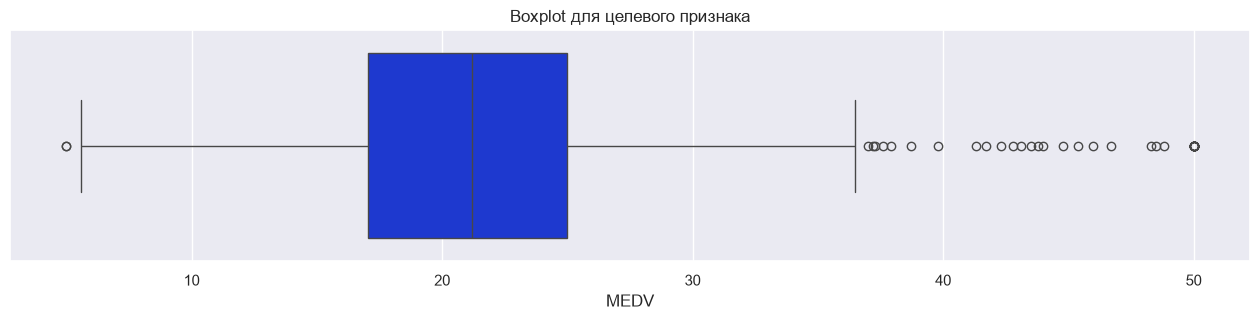

Наблюдаемый минимум:  5.06250
Нижний квартиль:      17.02500
Медиана:              21.20000
Верхний квартиль:     25.00000
Наблюдаемый максимум: 36.96250

Меньше минимума:   2
Больше максимума: 38


In [287]:
q1, median, q3 = y_df.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

plt.figure(figsize=(16, 3))
sns.boxplot(x=y_df)
plt.title('Boxplot для целевого признака')
plt.show()

print(
    f'Наблюдаемый минимум:  {lower:>2.5f}\n'
    f'Нижний квартиль:      {q1:>2.5f}\n'
    f'Медиана:              {median:>2.5f}\n'
    f'Верхний квартиль:     {q3:>2.5f}\n'
    f'Наблюдаемый максимум: {upper:>2.5f}\n'
)

count_rows_lower = len(df.query('MEDV < @lower'))
count_rows_upper = len(df.query('MEDV > @upper'))

print(
    f'Меньше минимума:  {count_rows_lower:>2}\n'
    f'Больше максимума: {count_rows_upper:>2}'
)

Можно считать выбросами наблюдения с меньше минимума и больше максимума

15. Отфильтруйте  исходные  данные,  удалив  выбросы. Пересоздайте  тестовую  и обучающую выборки, переобучите модель. Посчитайте показатели R2 и RMSE. Как они изменились? О чем это говорит?

*Для сравнения моделей удалю выбросы из train части, test часть оставлю без изменений*

In [288]:
# Находим индексы выбросов
query = '@upper < MEDV or MEDV < @lower'
outliers_idx = df.query(query).index

# Инициализируем  train часть без строк с выбросами
temp = [X_train_scaled, y_train]
without_outliers_data = []
for data in temp:
    use_index_mask = ~data.index.isin(outliers_idx)
    without_outliers_data.append(data[use_index_mask])
X_train_scaled_wo, y_train_wo = without_outliers_data

In [289]:
model_lr_wo = LinearRegression()
model_lr_wo.fit(X_train_scaled_wo, y_train_wo)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-1.56,-0.08,-1. ,-0.77, 3.29]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['PTRATIO','INDUS','TAX','NOX','RM_LSTAT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,21.66
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [290]:
y_pred_wo = model_lr_wo.predict(X_test_scaled)

In [291]:
model_lr_wo_r2 = r2_score(y_test, y_pred_wo) 
model_lr_wo_rmse = root_mean_squared_error(y_test, y_pred_wo)

report_model_lr_wo = f'Линейная регрессия после удаления выбросов из train:\nR²:   {model_lr_wo_r2:>2.10f}\nRMSE: {model_lr_wo_rmse:>2.10f}'

print(
    f'{report_model_lr}\n'
    f'{'-' * 35}\n'
    f'{report_model_lr_wo}'
)

Линейная регрессия до удаления выбросов из train:
R²:   0.6270229958
RMSE: 5.1106275791
-----------------------------------
Линейная регрессия после удаления выбросов из train:
R²:   0.6075659097
RMSE: 5.2422360133


Значение доли объясненной дисперсии (R²) уменьшилось, значение квадратного кореня среднеквадратичной ошибки (RMSE) увеличилось.

Исключение статистических выбросов по целевой переменной ухудшило качество прогнозирования модели, поскольку сократилось количество данных для обучения и модель получила меньше информации о крайних значениях стоимости жилья.

16. Из набора линейных моделей библиотеки sklearn возьмите гребневую регрессию (Ridge).  Обучите  модель.  Посчитайте  показатели  R2 и  RMSE. Сравните  их  с показателями линейной  модели.  Насколько  ожидаемы  такие  результаты  и почему? 

*Поскольку цель - улучшить качество прогнозирования, возьмем метрики лучшей модели и данные на которой она обучалась (с выбросами по целевому признаку)*

Для автоматического подбора гиперпараметра - коэффициента регуляризации воспользуемся `RidgeCV`

In [292]:
model_l2 = RidgeCV(alphas=np.logspace(-3, 1, 20), cv=5)
model_l2.fit(X_train_scaled, y_train)

,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.For an example on how regularization strength affects the model coefficients,see :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`.",array([1.0000...00000000e+01])
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used, else,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",5
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error <mean_squared_error>` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`coefficient of determination <r2_score>` (:math:`R^2`) otherwise.",None
,"gcv_mode gcv_mode: {'auto', 'svd', 'eigen'}, default='auto'Flag indicating which strategy to use when performingLeave-One-Out Cross-Validation. Options are:: 'auto' : same as 'eigen' 'svd' : use singular value decomposition of X when X is dense, fallback to 'eigen' when X is sparse 'eigen' : use eigendecomposition of X X' when n_samples <= n_features or X' X when n_features < n_samplesThe 'auto' mode is the default and is intended to pick the cheaperoption depending on the shape and sparsity of the training data.",None
,"store_cv_results store_cv_results: bool, default=FalseFlag indicating if the cross-validation values corresponding toeach alpha should be stored in the ``cv_results_`` attribute (seebelow). This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionchanged:: 1.5 Parameter name changed from `store_cv_values` to `store_cv_results`.",False
,"alpha_per_target alpha_per_target: bool, default=FalseFlag indicating whether to optimize the alpha value (picked from the`alphas` parameter list) for each target separately (for multi-outputsettings: multiple prediction targets). When set to `True`, afterfitting, the `alpha_` attribute will contain a value for each target.When set to `False`, a single alpha is used for all targets.This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionadded:: 0.24",False
Name,Type,Value
"alpha_ alpha_: float or ndarray of shape (n_targets,)Estimated regularization parameter, or, if ``alpha_per_target=True``,the estimated regularization parameter for each target.",float64,6.158
"best_score_ best_score_: float or ndarray of shape (n_targets,)Score of base estimator with best alpha, or, if``alpha_per_target=True``, a score for each target... versionadded:: 0.23",float64,0.6795
"coef_ coef_: ndarray of shape (n_features) or (n_targets, n_features)Weight vector(s).","ndarray[float64](5,)","[-1.85, 0.74,-0.7 ,-0.39, 5.27]"


In [293]:
print('Оптимальный alpha:', model_l2.alpha_)

Оптимальный alpha: 6.158482110660261


In [294]:
y_pred_l2 = model_l2.predict(X_test_scaled)

In [295]:
model_l2_r2 = r2_score(y_test, y_pred_l2) 
model_l2_rmse = root_mean_squared_error(y_test, y_pred_l2)

report_model_l2 = f'Линейная регрессия l2:\nR²:   {model_l2_r2:>2.10f}\nRMSE: {model_l2_rmse:>2.10f}'

print(
    f'{report_model_lr}\n'
    f'{'-' * 25}\n'
    f'{report_model_l2}'
)

Линейная регрессия до удаления выбросов из train:
R²:   0.6270229958
RMSE: 5.1106275791
-------------------------
Линейная регрессия l2:
R²:   0.6292990771
RMSE: 5.0950099881


Значение доли объясненной дисперсии (R²) увеличилсоь, значение квадратного кореня среднеквадратичной ошибки (RMSE) уменьшилось.

Регуляризация модели позволила получить чуть лучшее качество по сравнению с обычной линейной регрессией. Модель лучше сохраняет обобщающие способности к данным и уменьшает чувствительность к мультиколлинеарности.

17. Постройте полиномиальную регрессию с использованием полинома 3й степени. Посчитайте показатели R2 и RMSE. Сравните все полученные результаты. 

In [296]:
pf = PolynomialFeatures(degree=3, include_bias=False)
X_train_scaled_pf = pd.DataFrame(pf.fit_transform(X_train_scaled), columns=pf.get_feature_names_out(), index=X_train_scaled.index)
X_test_scaled_pf = pd.DataFrame(pf.fit_transform(X_test_scaled), columns=pf.get_feature_names_out(), index=X_test_scaled.index)

In [297]:
model_l2_pf = RidgeCV(alphas=np.logspace(-3, 1, 20), cv=5)
model_l2_pf.fit(X_train_scaled_pf, y_train)

,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.For an example on how regularization strength affects the model coefficients,see :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`.",array([1.0000...00000000e+01])
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used, else,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",5
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error <mean_squared_error>` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`coefficient of determination <r2_score>` (:math:`R^2`) otherwise.",None
,"gcv_mode gcv_mode: {'auto', 'svd', 'eigen'}, default='auto'Flag indicating which strategy to use when performingLeave-One-Out Cross-Validation. Options are:: 'auto' : same as 'eigen' 'svd' : use singular value decomposition of X when X is dense, fallback to 'eigen' when X is sparse 'eigen' : use eigendecomposition of X X' when n_samples <= n_features or X' X when n_features < n_samplesThe 'auto' mode is the default and is intended to pick the cheaperoption depending on the shape and sparsity of the training data.",None
,"store_cv_results store_cv_results: bool, default=FalseFlag indicating if the cross-validation values corresponding toeach alpha should be stored in the ``cv_results_`` attribute (seebelow). This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionchanged:: 1.5 Parameter name changed from `store_cv_values` to `store_cv_results`.",False
,"alpha_per_target alpha_per_target: bool, default=FalseFlag indicating whether to optimize the alpha value (picked from the`alphas` parameter list) for each target separately (for multi-outputsettings: multiple prediction targets). When set to `True`, afterfitting, the `alpha_` attribute will contain a value for each target.When set to `False`, a single alpha is used for all targets.This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionadded:: 0.24",False
Name,Type,Value
"alpha_ alpha_: float or ndarray of shape (n_targets,)Estimated regularization parameter, or, if ``alpha_per_target=True``,the estimated regularization parameter for each target.",float64,0.04833
"best_score_ best_score_: float or ndarray of shape (n_targets,)Score of base estimator with best alpha, or, if``alpha_per_target=True``, a score for each target... versionadded:: 0.23",float64,0.6742
"coef_ coef_: ndarray of shape (n_features) or (n_targets, n_features)Weight vector(s).","ndarray[float64](55,)","[-0.65,-1.93, 1.05,...,-3.25,-0.87,-0.21

In [298]:
print('Оптимальный alpha:', model_l2_pf.alpha_)

Оптимальный alpha: 0.04832930238571752


In [299]:
y_pred_l2_pf_train = model_l2_pf.predict(X_train_scaled_pf)
y_pred_l2_pf_test = model_l2_pf.predict(X_test_scaled_pf)

In [300]:
model_l2_pf_r2_train = r2_score(y_train, y_pred_l2_pf_train) 
model_l2_pf_rmse_train = root_mean_squared_error(y_train, y_pred_l2_pf_train)
model_l2_pf_r2_test = r2_score(y_test, y_pred_l2_pf_test) 
model_l2_pf_rmse_test = root_mean_squared_error(y_test, y_pred_l2_pf_test)

report_model_l2_pf = f'''Линейная регрессия l2 + полином 3-й степени:
R² (train):   {model_l2_pf_r2_train:>2.10f}
RMSE (train): {model_l2_pf_rmse_train:>2.10f}
R² (test):    {model_l2_pf_r2_test:>2.10f}
RMSE (test):  {model_l2_pf_rmse_test:>2.10f}'''

print(
    f'{report_model_l2}\n'
    f'{'-' * 45}\n'
    f'{report_model_l2_pf}'
)

Линейная регрессия l2:
R²:   0.6292990771
RMSE: 5.0950099881
---------------------------------------------
Линейная регрессия l2 + полином 3-й степени:
R² (train):   0.8356874185
RMSE (train): 3.8172665929
R² (test):    0.7946584438
RMSE (test):  3.7920288309


Значение доли объясненной дисперсии (R²) существенно увеличилсоь, значение квадратного кореня среднеквадратичной ошибки (RMSE) существенно уменьшилось.

Полином 3-й степени и линейная регрессия с l2 регуляризацией позволили заметно улучшить качество модели. Применение полинома помогло модели увидеть нелинейные связи признаков и связи признаков друг с другом.

Модель чуть чуть переобучилось на тестовых данных но не критично.

In [303]:
reports = [
    report_model_lr,
    report_model_lr_wo,
    report_model_l2,
    report_model_l2_pf
]
print(f'\n{'-'*60}\n'.join(reports))

Линейная регрессия до удаления выбросов из train:
R²:   0.6270229958
RMSE: 5.1106275791
------------------------------------------------------------
Линейная регрессия после удаления выбросов из train:
R²:   0.6075659097
RMSE: 5.2422360133
------------------------------------------------------------
Линейная регрессия l2:
R²:   0.6292990771
RMSE: 5.0950099881
------------------------------------------------------------
Линейная регрессия l2 + полином 3-й степени:
R² (train):   0.8356874185
RMSE (train): 3.8172665929
R² (test):    0.7946584438
RMSE (test):  3.7920288309


- Бейзланом стала модель линейной регрессии обученная на перемешенной тренировочной выборке (75% от общего количества данных) на отобранных и стандартизированных 6 признаках 2 из которых были преобразованы при помощи PCA.
- Удаление строк из тренировочной выборки с выбросами по целевой переменной не помогло улучить результаты модели:
- Регуляризация l2 помогла улучить результаты в сравнении с бейзлайном
- Несмотря на незначительное переобучение, лучшее качество было достигнуто при применении линейной регрессии с l2 регуляризацией на данных полинома 3-й степени.

Лучший результат на тестовой выборке: `R²`: 0.7946584438 и `RMSE`:  3.7920288309
